In [1]:
!pip install ucimlrepo pandas numpy scikit-learn xgboost shap lime plotly matplotlib joblib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=9b9f6ba66b7dd922152ca57fb603ccb9905e4f0a0d242b5523fd259a5f09e02d
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [2]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

import plotly.graph_objects as go
import matplotlib.pyplot as plt
import shap


from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)

from lime.lime_tabular import LimeTabularExplainer
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

**Module 1 :**  Données


In [3]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=350)
X = dataset.data.features.copy()
y = dataset.data.targets.copy()

print("X :", X.shape, "| y :", y.shape)
print(X.columns.tolist())

X : (30000, 23) | y : (30000, 1)
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']


In [4]:
noms = (
    ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
    + ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)
if X.columns[0].startswith("X"):
    X.columns = noms
else:
    X = X.rename(columns={"PAY_0": "PAY_1"})

if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]
y = y.rename("DEFAULT")

df = pd.concat([X, y], axis=1)
print(df.head())

   LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_1  PAY_2  PAY_3  PAY_4  \
0      20000    2          2         1   24      2      2     -1     -1   
1     120000    2          2         2   26     -1      2      0      0   
2      90000    2          2         2   34      0      0      0      0   
3      50000    2          2         1   37      0      0      0      0   
4      50000    1          2         1   57     -1      0     -1      0   

   PAY_5  ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0     -2  ...          0          0          0         0       689         0   
1      0  ...       3272       3455       3261         0      1000      1000   
2      0  ...      14331      14948      15549      1518      1500      1000   
3      0  ...      28314      28959      29547      2000      2019      1200   
4      0  ...      20940      19146      19131      2000     36681     10000   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  DEFAULT  
0         0         0    

In [5]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def visualiser(d, titre):
    n = len(d)

    #rep de DEFAULT
    cl = d["DEFAULT"].value_counts().sort_index()
    fig = px.bar(x=["Pas de défaut (0)", "Défaut (1)"], y=cl.values,
                 text=[f"{v:,} ({v / n:.1%})" for v in cl.values],
                 title=f"[{titre}] Répartition de la cible", labels={"x": "", "y": "Effectif"})
    fig.show()

    #var cat
    cats = ["SEX", "EDUCATION", "MARRIAGE"]
    fig = make_subplots(rows=2, cols=3, vertical_spacing=0.18,
                        subplot_titles=[f"{c} : effectifs" for c in cats] + [f"{c} : taux de défaut" for c in cats])
    for j, c in enumerate(cats, start=1):
        vc = d[c].value_counts().sort_index()
        taux = d.groupby(c)["DEFAULT"].mean().sort_index()
        fig.add_trace(go.Bar(x=vc.index.astype(str), y=vc.values, showlegend=False), row=1, col=j)
        fig.add_trace(go.Bar(x=taux.index.astype(str), y=taux.values, showlegend=False), row=2, col=j)
    fig.update_layout(title=f"[{titre}] Variables catégorielles", height=600)
    fig.show()

    #distribution des var
    fig = make_subplots(rows=2, cols=2,
                        subplot_titles=["AGE", "LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"])
    for k, c in enumerate(["AGE", "LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]):
        r, col = divmod(k, 2)
        for classe, couleur in [(0, "#1f77b4"), (1, "#d62728")]:
            fig.add_trace(go.Histogram(x=d.loc[d["DEFAULT"] == classe, c], opacity=0.6,
                                       marker_color=couleur, showlegend=(k == 0),
                                       name="Défaut" if classe else "Pas de défaut"),
                          row=r + 1, col=col + 1)
    fig.update_layout(barmode="overlay", title=f"[{titre}] Distributions selon la classe", height=600)
    fig.show()

    #status de remboursement
    pay = [f"PAY_{i}" for i in range(1, 7)]
    prop = pd.DataFrame({c: d[c].value_counts(normalize=True) for c in pay}).sort_index().fillna(0)
    fig = px.imshow(prop.T.round(3), text_auto=True, aspect="auto", color_continuous_scale="Blues",
                    title=f"[{titre}] Part de chaque statut de remboursement (-2 à 8)",
                    labels={"x": "Statut", "y": "Mois"})
    fig.show()

    #taus defaut selon pay1
    t = d.groupby("PAY_1")["DEFAULT"].agg(["mean", "size"]).reset_index()
    fig = px.bar(t, x="PAY_1", y="mean", text=t["size"].map("n={:,}".format),
                 title=f"[{titre}] Taux de défaut selon PAY_1", labels={"mean": "Taux de défaut"})
    fig.show()

    #coorelation
    fig = px.imshow(d.corr(numeric_only=True).round(2), color_continuous_scale="RdBu_r",
                    zmin=-1, zmax=1, aspect="auto", title=f"[{titre}] Matrice de corrélation")
    fig.update_layout(height=700)
    fig.show()




In [6]:
print(df.head(40))
print(df.dtypes)
print("\nValeurs manquantes :", int(df.isna().sum().sum()))
print("Doublons :", int(df.duplicated().sum()))

print(df["DEFAULT"].value_counts())
print(df["DEFAULT"].value_counts(normalize=True).round(3))


    LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_1  PAY_2  PAY_3  PAY_4  \
0       20000    2          2         1   24      2      2     -1     -1   
1      120000    2          2         2   26     -1      2      0      0   
2       90000    2          2         2   34      0      0      0      0   
3       50000    2          2         1   37      0      0      0      0   
4       50000    1          2         1   57     -1      0     -1      0   
5       50000    1          1         2   37      0      0      0      0   
6      500000    1          1         2   29      0      0      0      0   
7      100000    2          2         2   23      0     -1     -1      0   
8      140000    2          3         1   28      0      0      2      0   
9       20000    1          3         2   35     -2     -2     -2     -2   
10     200000    2          3         2   34      0      0      2      0   
11     260000    2          1         2   51     -1     -1     -1     -1   
12     63000

In [7]:
#val non doc
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{col}:\n", df[col].value_counts().sort_index())
df_brut = df.copy()
visualiser(df_brut, "AVANT nettoyage")


SEX:
 SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
 EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
 MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [8]:
#0, 5, 6 non documentés -> 4(autres)
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
# 0 non documenté -> 3(autres)
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
print(df.head())



   LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_1  PAY_2  PAY_3  PAY_4  \
0      20000    2          2         1   24      2      2     -1     -1   
1     120000    2          2         2   26     -1      2      0      0   
2      90000    2          2         2   34      0      0      0      0   
3      50000    2          2         1   37      0      0      0      0   
4      50000    1          2         1   57     -1      0     -1      0   

   PAY_5  ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0     -2  ...          0          0          0         0       689         0   
1      0  ...       3272       3455       3261         0      1000      1000   
2      0  ...      14331      14948      15549      1518      1500      1000   
3      0  ...      28314      28959      29547      2000      2019      1200   
4      0  ...      20940      19146      19131      2000     36681     10000   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  DEFAULT  
0         0         0    

In [9]:
#les doublons
df = df.drop_duplicates().reset_index(drop=True)

In [10]:
#stats
print(df.describe().T.round(1))

for col in ["SEX", "EDUCATION", "MARRIAGE", "PAY_1"]:
    print(f"\nTaux de défaut par {col} :")
    print(df.groupby(col)["DEFAULT"].mean().round(3))

df["AGE_TRANCHE"] = pd.cut(df["AGE"], [20, 30, 40, 50, 60, 80])
print("\nTaux de défaut par tranche d'âge :")
print(df.groupby("AGE_TRANCHE", observed=True)["DEFAULT"].mean().round(3))
df = df.drop(columns="AGE_TRANCHE")


             count      mean       std       min      25%       50%       75%  \
LIMIT_BAL  29965.0  167442.0  129760.1   10000.0  50000.0  140000.0  240000.0   
SEX        29965.0       1.6       0.5       1.0      1.0       2.0       2.0   
EDUCATION  29965.0       1.8       0.7       1.0      1.0       2.0       2.0   
MARRIAGE   29965.0       1.6       0.5       1.0      1.0       2.0       2.0   
AGE        29965.0      35.5       9.2      21.0     28.0      34.0      41.0   
PAY_1      29965.0      -0.0       1.1      -2.0     -1.0       0.0       0.0   
PAY_2      29965.0      -0.1       1.2      -2.0     -1.0       0.0       0.0   
PAY_3      29965.0      -0.2       1.2      -2.0     -1.0       0.0       0.0   
PAY_4      29965.0      -0.2       1.2      -2.0     -1.0       0.0       0.0   
PAY_5      29965.0      -0.3       1.1      -2.0     -1.0       0.0       0.0   
PAY_6      29965.0      -0.3       1.1      -2.0     -1.0       0.0       0.0   
BILL_AMT1  29965.0   51283.0

In [11]:
visualiser(df, "APRÈS nettoyage")

comparaison = pd.DataFrame({
    "Avant": [len(df_brut), int(df_brut.duplicated().sum()),
              int((~df_brut["EDUCATION"].isin([1, 2, 3, 4])).sum()),
              int((~df_brut["MARRIAGE"].isin([1, 2, 3])).sum()),
              round(df_brut["DEFAULT"].mean(), 4)],
    "Après": [len(df), int(df.duplicated().sum()),
              int((~df["EDUCATION"].isin([1, 2, 3, 4])).sum()),
              int((~df["MARRIAGE"].isin([1, 2, 3])).sum()),
              round(df["DEFAULT"].mean(), 4)],
}, index=["Lignes", "Doublons", "EDUCATION hors codes 1-4", "MARRIAGE hors codes 1-3", "Taux de défaut"])
print(comparaison)


                               Avant       Après
Lignes                    30000.0000  29965.0000
Doublons                     35.0000      0.0000
EDUCATION hors codes 1-4    345.0000      0.0000
MARRIAGE hors codes 1-3      54.0000      0.0000
Taux de défaut                0.2212      0.2213


In [12]:
#Sauvegarde
df.to_csv("credit_default_clean.csv", index=False)
print("Fichier enregistré :", df.shape)

Fichier enregistré : (29965, 24)


**Module 2 :** Préparation

In [13]:
CHEMIN_CSV = "credit_default_clean.csv"
df = pd.read_csv(CHEMIN_CSV)

CIBLE = "DEFAULT"
X = df.drop(columns=CIBLE)
y = df[CIBLE]
print(X.shape, "| taux de défaut :", round(y.mean(), 3))

(29965, 23) | taux de défaut : 0.221


In [14]:
#train / test
TEST_SIZE = 0.2
SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)
print("Train :", X_train.shape, "défauts :", round(y_train.mean(), 3))
print("Test  :", X_test.shape, "défauts :", round(y_test.mean(), 3))


Train : (23972, 23) défauts : 0.221
Test  : (5993, 23) défauts : 0.221


In [15]:
#préprocesseur
colonnes_cat = ["SEX", "EDUCATION", "MARRIAGE"]
colonnes_num = [c for c in X.columns if c not in colonnes_cat]

def creer_preprocesseur():
    return ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), colonnes_cat),
            ("num", StandardScaler(), colonnes_num),
        ]
    )

**Module 3 :** Modélisation et comparaison

In [16]:
#les 5 modeles
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight :", round(ratio, 2))

modeles = {
    "Régression logistique": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=SEED
    ),
    "Arbre de décision": DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=SEED
    ),
    "k plus proches voisins": KNeighborsClassifier(n_neighbors=25),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, class_weight="balanced",
        n_jobs=-1, random_state=SEED
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        scale_pos_weight=ratio, eval_metric="logloss",
        n_jobs=-1, random_state=SEED
    ),
}

scale_pos_weight : 3.52


In [17]:
#train
pipelines = {}
for nom, modele in modeles.items():
    pipe = Pipeline([("prep", creer_preprocesseur()), ("clf", modele)])
    pipe.fit(X_train, y_train)
    pipelines[nom] = pipe
    print("Entraîné :", nom)


Entraîné : Régression logistique
Entraîné : Arbre de décision
Entraîné : k plus proches voisins
Entraîné : Random Forest
Entraîné : XGBoost


In [18]:
#eval
def ks_stat(y_true, proba):
    fpr, tpr, _ = roc_curve(y_true, proba)
    return float(np.max(tpr - fpr))


def evaluer(pipe, X_te, y_te, seuil=0.5):
    proba = pipe.predict_proba(X_te)[:, 1]
    pred = (proba >= seuil).astype(int)
    auc = roc_auc_score(y_te, proba)
    return {
        "AUC-ROC": auc,
        "PR-AUC": average_precision_score(y_te, proba),
        "Précision": precision_score(y_te, pred, zero_division=0),
        "Rappel": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
        "Gini": 2 * auc - 1,
        "KS": ks_stat(y_te, proba),
    }


resultats = pd.DataFrame(
    {nom: evaluer(p, X_test, y_test) for nom, p in pipelines.items()}
).T.round(3).sort_values("AUC-ROC", ascending=False)

print(resultats)

                        AUC-ROC  PR-AUC  Précision  Rappel     F1   Gini  \
XGBoost                   0.771   0.552      0.460   0.621  0.529  0.542   
Random Forest             0.768   0.550      0.486   0.575  0.527  0.536   
Arbre de décision         0.746   0.505      0.387   0.669  0.491  0.492   
k plus proches voisins    0.743   0.493      0.636   0.345  0.447  0.487   
Régression logistique     0.719   0.503      0.372   0.633  0.469  0.438   

                           KS  
XGBoost                 0.420  
Random Forest           0.411  
Arbre de décision       0.390  
k plus proches voisins  0.363  
Régression logistique   0.363  


In [19]:
Path("../models").mkdir(exist_ok=True)
joblib.dump(pipelines, "../models/pipelines_base.joblib")
joblib.dump((X_train, X_test, y_train, y_test), "../models/split.joblib")
resultats.to_csv("resultats_base.csv")


In [20]:
from pathlib import Path

print("Dossier models :", Path("../models").exists())
print("Split :", Path("../models/split.joblib").exists())
print("Pipelines :", Path("../models/pipelines_base.joblib").exists())

Dossier models : True
Split : True
Pipelines : True


In [21]:
# Apres modif des hyperparamètres
SEED = 42

X_train, X_test, y_train, y_test = joblib.load(
    "../models/split.joblib"
)

pipelines_base = joblib.load(
    "../models/pipelines_base.joblib"
)
colonnes_cat = ["SEX", "EDUCATION", "MARRIAGE"]
colonnes_num = [c for c in X_train.columns if c not in colonnes_cat]
ratio = (y_train == 0).sum() / (y_train == 1).sum()


def creer_preprocesseur():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), colonnes_cat),
        ("num", StandardScaler(), colonnes_num),
    ])

In [22]:
espaces = {
    "Régression logistique": (
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED
        ),
        {
            "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]
        },
    ),

    "Arbre de décision": (
        DecisionTreeClassifier(
            class_weight="balanced",
            random_state=SEED
        ),
        {
            "clf__max_depth": [3, 4, 5, 6, 8, 10],
            "clf__min_samples_leaf": [20, 50, 100, 150],
            "clf__min_samples_split": [20, 50, 100]
        },
    ),

    "k plus proches voisins": (
        KNeighborsClassifier(),
        {
            "clf__n_neighbors": [15, 25, 50, 75, 100],
            "clf__weights": ["uniform", "distance"],
            "clf__p": [1, 2]
        },
    ),

    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            n_jobs=1,
            random_state=SEED
        ),
        {
            "clf__n_estimators": [200, 300, 500],
            "clf__max_depth": [6, 8, 10, 14, None],
            "clf__min_samples_leaf": [5, 10, 20, 50],
            "clf__min_samples_split": [10, 20, 50],
            "clf__max_features": ["sqrt", 0.3, 0.5]
        },
    ),

    "XGBoost": (
        XGBClassifier(
            scale_pos_weight=ratio,
            eval_metric="logloss",
            n_jobs=1,
            random_state=SEED
        ),
        {
            "clf__n_estimators": [200, 300, 500, 700],
            "clf__max_depth": [2, 3, 4, 5],
            "clf__learning_rate": [0.01, 0.02, 0.03, 0.05],
            "clf__subsample": [0.7, 0.8, 0.9, 1.0],
            "clf__colsample_bytree": [0.6, 0.8, 1.0],
            "clf__min_child_weight": [3, 5, 7, 10],
            "clf__reg_alpha": [0, 0.1, 1],
            "clf__reg_lambda": [1, 5, 10],
            "clf__gamma": [0, 0.1, 0.3]
        },
    ),
}

In [23]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
pipelines_opt, meilleurs_params = {}, {}

for nom, (modele, grille) in espaces.items():
    taille = int(np.prod([len(v) for v in grille.values()]))
    recherche = RandomizedSearchCV(
        Pipeline([("prep", creer_preprocesseur()), ("clf", modele)]),
        param_distributions=grille,
        n_iter=min(12, taille),
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        random_state=SEED,
        refit=True,
    )
    recherche.fit(X_train, y_train)
    pipelines_opt[nom] = recherche.best_estimator_
    meilleurs_params[nom] = recherche.best_params_
    print(f"{nom:25s} AUC CV = {recherche.best_score_:.3f} | {recherche.best_params_}")



Régression logistique     AUC CV = 0.726 | {'clf__C': 100}
Arbre de décision         AUC CV = 0.764 | {'clf__min_samples_split': 20, 'clf__min_samples_leaf': 100, 'clf__max_depth': 8}
k plus proches voisins    AUC CV = 0.761 | {'clf__weights': 'uniform', 'clf__p': 2, 'clf__n_neighbors': 100}
Random Forest             AUC CV = 0.787 | {'clf__n_estimators': 500, 'clf__min_samples_split': 20, 'clf__min_samples_leaf': 20, 'clf__max_features': 0.3, 'clf__max_depth': 14}
XGBoost                   AUC CV = 0.787 | {'clf__subsample': 0.9, 'clf__reg_lambda': 1, 'clf__reg_alpha': 0.1, 'clf__n_estimators': 300, 'clf__min_child_weight': 5, 'clf__max_depth': 5, 'clf__learning_rate': 0.02, 'clf__gamma': 0.1, 'clf__colsample_bytree': 0.8}


In [24]:
#eval apres modif
def ks_stat(y_true, proba):
    fpr, tpr, _ = roc_curve(y_true, proba)
    return float(np.max(tpr - fpr))


def evaluer(pipe, X_te, y_te, seuil=0.5):
    proba = pipe.predict_proba(X_te)[:, 1]
    pred = (proba >= seuil).astype(int)
    auc = roc_auc_score(y_te, proba)
    return {
        "AUC-ROC": auc,
        "PR-AUC": average_precision_score(y_te, proba),
        "Précision": precision_score(y_te, pred, zero_division=0),
        "Rappel": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
        "Gini": 2 * auc - 1,
        "KS": ks_stat(y_te, proba),
    }


res_opt = pd.DataFrame(
    {nom: evaluer(p, X_test, y_test) for nom, p in pipelines_opt.items()}
).T.round(3).sort_values("AUC-ROC", ascending=False)
print("\n=== Modèles optimisés (test) ===")
print(res_opt)

res_base = pd.DataFrame(
    {nom: evaluer(p, X_test, y_test) for nom, p in pipelines_base.items()}
).T.round(3)
comparaison = pd.DataFrame({
    "AUC base": res_base["AUC-ROC"],
    "AUC optimisé": res_opt["AUC-ROC"],
}).assign(Gain=lambda d: (d["AUC optimisé"] - d["AUC base"]).round(3))
print("\n=== Gain de l'optimisation ===")
print(comparaison.sort_values("AUC optimisé", ascending=False))

meilleur_nom = res_opt.index[0]
meilleur = pipelines_opt[meilleur_nom]
print("\nMeilleur modèle :", meilleur_nom)


=== Modèles optimisés (test) ===
                        AUC-ROC  PR-AUC  Précision  Rappel     F1   Gini  \
XGBoost                   0.775   0.557      0.463   0.623  0.531  0.551   
Random Forest             0.774   0.554      0.500   0.570  0.533  0.548   
Arbre de décision         0.754   0.516      0.402   0.646  0.496  0.509   
k plus proches voisins    0.747   0.511      0.655   0.316  0.426  0.494   
Régression logistique     0.719   0.503      0.371   0.632  0.468  0.438   

                           KS  
XGBoost                 0.421  
Random Forest           0.415  
Arbre de décision       0.387  
k plus proches voisins  0.377  
Régression logistique   0.363  

=== Gain de l'optimisation ===
                        AUC base  AUC optimisé   Gain
XGBoost                    0.771         0.775  0.004
Random Forest              0.768         0.774  0.006
Arbre de décision          0.746         0.754  0.008
k plus proches voisins     0.743         0.747  0.004
Régression logi

In [25]:
#courbes ROC
fig = go.Figure()
for nom, p in pipelines_opt.items():
    proba = p.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines",
                             name=f"{nom} (AUC={roc_auc_score(y_test, proba):.3f})"))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines",
                         line=dict(dash="dash", color="grey"), name="Hasard"))
fig.update_layout(title="Courbes ROC - tous les modèles", width=800, height=550,
                  xaxis_title="Taux de faux positifs", yaxis_title="Taux de vrais positifs (rappel)")
fig.show()

In [26]:
#courbes précision rappel
fig = go.Figure()
for nom, p in pipelines_opt.items():
    proba = p.predict_proba(X_test)[:, 1]
    prec, rapp, _ = precision_recall_curve(y_test, proba)
    fig.add_trace(go.Scatter(x=rapp, y=prec, mode="lines",
                             name=f"{nom} (PR-AUC={average_precision_score(y_test, proba):.3f})"))
fig.add_hline(y=y_test.mean(), line_dash="dash", line_color="grey",
              annotation_text="Taux de défaut (hasard)")
fig.update_layout(title="Courbes précision-rappel", width=800, height=550,
                  xaxis_title="Rappel", yaxis_title="Précision")
fig.show()


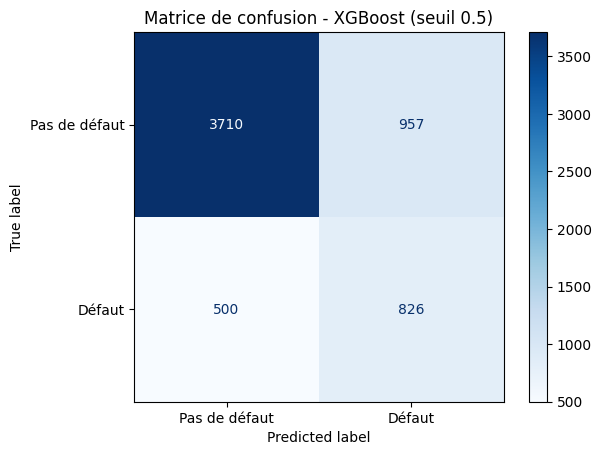

In [27]:
#matrice de confusion
proba_best = meilleur.predict_proba(X_test)[:, 1]
pred_best = (proba_best >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_best, display_labels=["Pas de défaut", "Défaut"], cmap="Blues"
)
plt.title(f"Matrice de confusion - {meilleur_nom} (seuil 0.5)")
plt.show()

 Seuil  Précision  Rappel    F1  Clients signalés (%)
  0.10      0.223   0.998 0.365                98.799
  0.15      0.233   0.989 0.377                94.076
  0.20      0.250   0.968 0.398                85.533
  0.25      0.274   0.927 0.423                74.921
  0.30      0.304   0.874 0.451                63.541
  0.35      0.337   0.811 0.476                53.245
  0.40      0.375   0.723 0.494                42.666
  0.45      0.420   0.670 0.516                35.291
  0.50      0.463   0.623 0.531                29.751
  0.55      0.504   0.563 0.532                24.729
  0.60      0.548   0.521 0.534                21.041
  0.65      0.595   0.464 0.521                17.237
  0.70      0.633   0.416 0.502                14.517
  0.75      0.658   0.370 0.473                12.431
  0.80      0.695   0.317 0.435                10.078
  0.85      0.715   0.259 0.380                 8.009
  0.90      0.790   0.150 0.252                 4.205


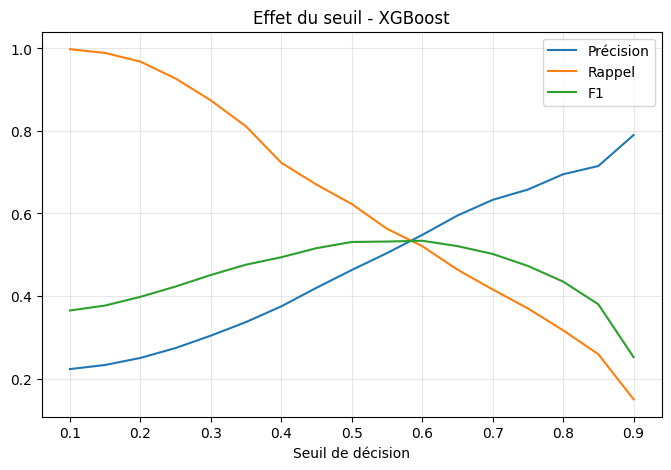

In [28]:
#effet du seuil
seuils = np.round(np.arange(0.10, 0.91, 0.05), 2)
lignes = []
for s in seuils:
    pred = (proba_best >= s).astype(int)
    lignes.append({
        "Seuil": s,
        "Précision": precision_score(y_test, pred, zero_division=0),
        "Rappel": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Clients signalés (%)": pred.mean() * 100,
    })
table_seuils = pd.DataFrame(lignes).round(3)
print(table_seuils.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(table_seuils["Seuil"], table_seuils["Précision"], label="Précision")
plt.plot(table_seuils["Seuil"], table_seuils["Rappel"], label="Rappel")
plt.plot(table_seuils["Seuil"], table_seuils["F1"], label="F1")
plt.xlabel("Seuil de décision")
plt.title(f"Effet du seuil - {meilleur_nom}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [29]:
joblib.dump(pipelines_opt, "../models/pipelines_opt.joblib")
joblib.dump(meilleurs_params, "../models/meilleurs_params.joblib")
res_opt.to_csv("resultats_optimises.csv")


**Module 4 :** Explainable AI

In [30]:
SEED = 42
X_train, X_test, y_train, y_test = joblib.load("../models/split.joblib")
pipelines = joblib.load("../models/pipelines_opt.joblib")

MODELE_XAI = "XGBoost"
SEUIL = 0.5
N_ECHANTILLON = 1000

pipe = pipelines[MODELE_XAI]
prep, clf = pipe.named_steps["prep"], pipe.named_steps["clf"]

colonnes_cat = ["SEX", "EDUCATION", "MARRIAGE"]
noms = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]


In [31]:
def transformer(X):
    Xt = prep.transform(X)
    Xt = Xt.toarray() if hasattr(Xt, "toarray") else np.asarray(Xt)
    return pd.DataFrame(Xt, columns=noms, index=X.index)


Xtr_t = transformer(X_train)
Xs = X_test.iloc[:N_ECHANTILLON]
Xs_t = transformer(Xs)
proba_s = pipe.predict_proba(Xs)[:, 1]
print("Modèle expliqué :", MODELE_XAI, "| variables après encodage :", len(noms))


Modèle expliqué : XGBoost | variables après encodage : 28


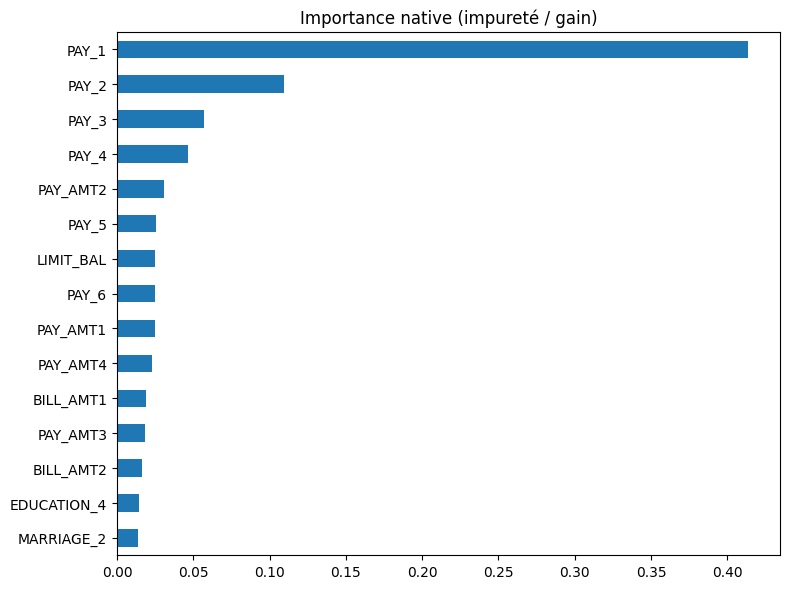

In [32]:
if isinstance(clf, LogisticRegression):
    imp = pd.Series(clf.coef_[0], index=noms).sort_values(key=abs, ascending=False)
    titre = "Coefficients de la régression logistique (variables standardisées)"
else:
    imp = pd.Series(clf.feature_importances_, index=noms).sort_values(ascending=False)
    titre = "Importance native (impureté / gain)"

imp.head(15).iloc[::-1].plot.barh(figsize=(8, 6), title=titre)
plt.tight_layout()
plt.show()


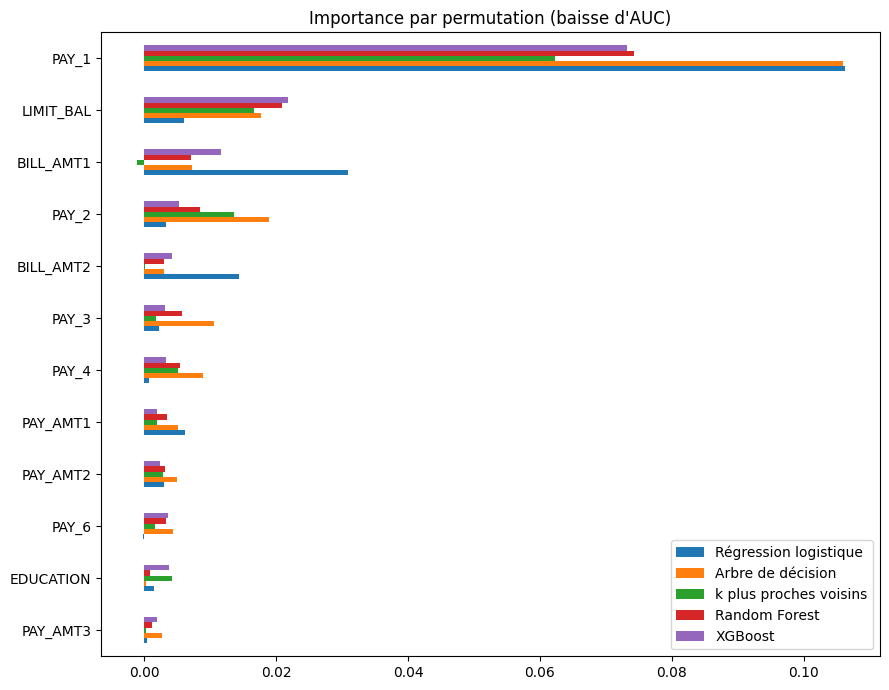

In [33]:
perm_resultats = {}
for nom, p in pipelines.items():
    r = permutation_importance(
        p, X_test, y_test, scoring="roc_auc", n_repeats=5,
        random_state=SEED, n_jobs=-1,
    )
    perm_resultats[nom] = pd.Series(r.importances_mean, index=X_test.columns)

perm = pd.DataFrame(perm_resultats)
top = perm.mean(axis=1).sort_values(ascending=False).head(12).index
perm.loc[top].iloc[::-1].plot.barh(figsize=(9, 7),
                                   title="Importance par permutation (baisse d'AUC)")
plt.tight_layout()
plt.show()


In [34]:
if isinstance(clf, LogisticRegression):
    explainer = shap.LinearExplainer(clf, Xtr_t)
else:
    explainer = shap.TreeExplainer(clf)

expl = explainer(Xs_t)
if expl.values.ndim == 3:
    expl = expl[:, :, 1]


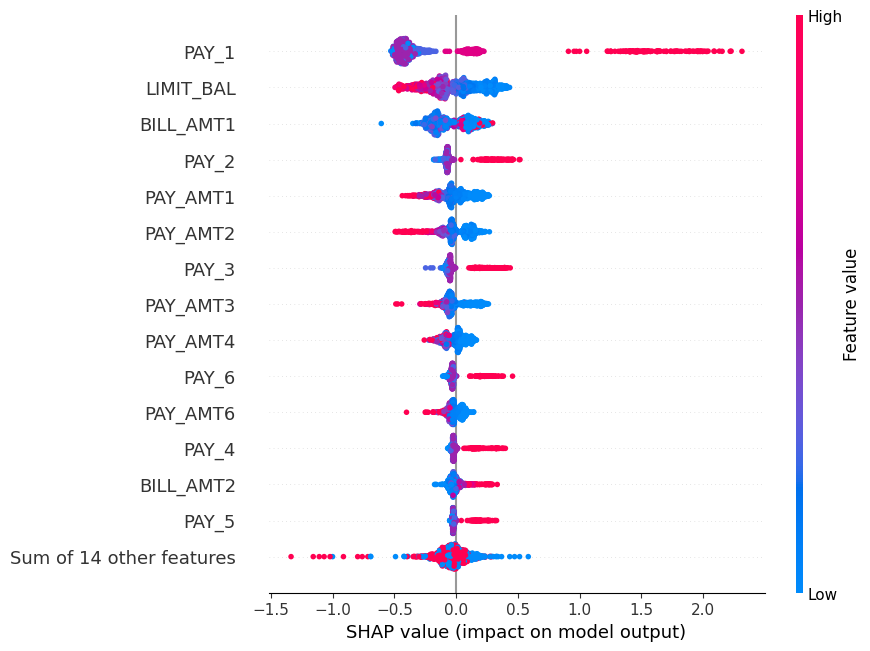

Variables principales : ['PAY_1', 'LIMIT_BAL', 'BILL_AMT1']


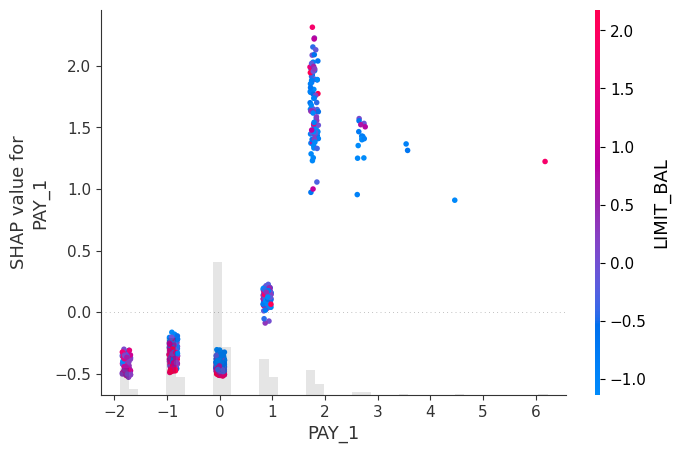

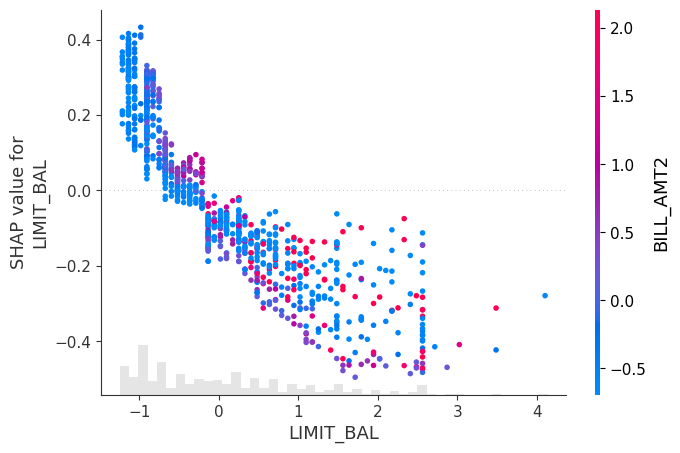

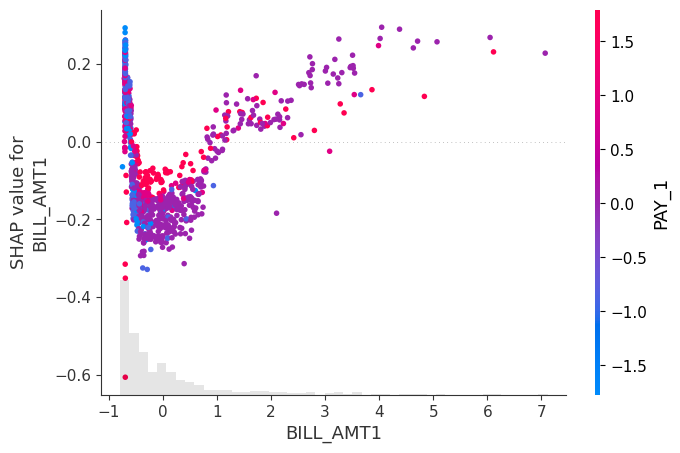

In [35]:
shap.plots.beeswarm(expl, max_display=15)

variables_principales = (
    pd.Series(np.abs(expl.values).mean(axis=0), index=noms)
    .sort_values(ascending=False).head(3).index.tolist()
)
print("Variables principales :", variables_principales)
for v in variables_principales:
    shap.plots.scatter(expl[:, v], color=expl)


In [36]:
IDX = int(np.argmax(proba_s))      # client le plus risqué ; remplace par un entier (0..999) si tu veux
print("Client", IDX, "| probabilité de défaut :", round(float(proba_s[IDX]), 3),
      "| décision :", "REFUS / alerte" if proba_s[IDX] >= SEUIL else "ACCEPTÉ")
print("Défaut réel :", int(y_test.iloc[IDX]))
print(Xs.iloc[IDX].to_string())


Client 786 | probabilité de défaut : 0.958 | décision : REFUS / alerte
Défaut réel : 1
LIMIT_BAL    200000
SEX               1
EDUCATION         1
MARRIAGE          1
AGE              49
PAY_1             2
PAY_2             2
PAY_3             2
PAY_4             2
PAY_5             2
PAY_6             2
BILL_AMT1      2500
BILL_AMT2      2500
BILL_AMT3      2500
BILL_AMT4      2500
BILL_AMT5      2500
BILL_AMT6      2500
PAY_AMT1          0
PAY_AMT2          0
PAY_AMT3          0
PAY_AMT4          0
PAY_AMT5          0
PAY_AMT6          0


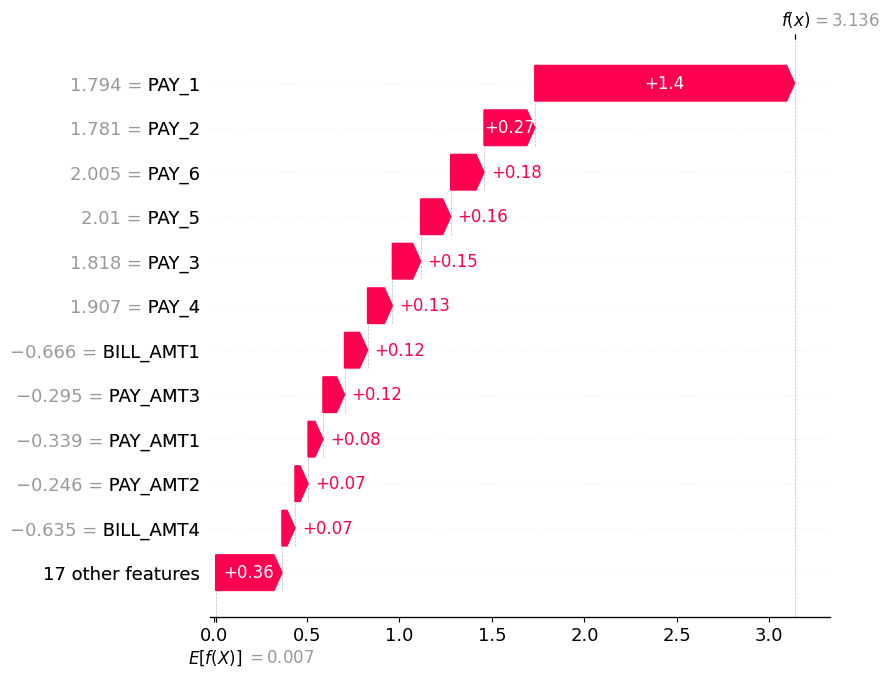

In [37]:
shap.plots.waterfall(expl[IDX], max_display=12)


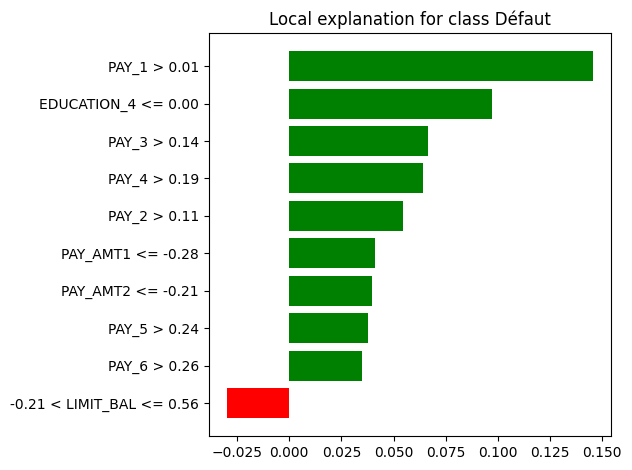

In [38]:
lime_exp = LimeTabularExplainer(
    training_data=Xtr_t.values,
    feature_names=noms,
    class_names=["Pas de défaut", "Défaut"],
    mode="classification",
    discretize_continuous=True,
    random_state=SEED,
)
exp = lime_exp.explain_instance(
    Xs_t.iloc[IDX].values, clf.predict_proba, num_features=10, num_samples=3000
)
fig = exp.as_pyplot_figure(label=1)
plt.tight_layout()
plt.show()


In [39]:
shap_loc = pd.Series(expl.values[IDX], index=noms)
lime_loc = pd.Series({noms[i]: w for i, w in exp.as_map()[1]})

comp = pd.DataFrame({
    "SHAP": shap_loc.loc[lime_loc.index],
    "LIME": lime_loc,
})
comp["Même sens ?"] = np.sign(comp["SHAP"]) == np.sign(comp["LIME"])
print(comp.round(3))

top5_shap = set(shap_loc.abs().sort_values(ascending=False).head(5).index)
top5_lime = set(lime_loc.abs().sort_values(ascending=False).head(5).index)
print("\nVariables communes dans le top 5 :", top5_shap & top5_lime)


              SHAP   LIME  Même sens ?
PAY_1        1.404  0.146         True
EDUCATION_4  0.010  0.097         True
PAY_3        0.153  0.066         True
PAY_4        0.134  0.064         True
PAY_2        0.275  0.054         True
PAY_AMT1     0.081  0.041         True
PAY_AMT2     0.071  0.040         True
PAY_5        0.162  0.038         True
PAY_6        0.180  0.035         True
LIMIT_BAL   -0.026 -0.030         True

Variables communes dans le top 5 : {'PAY_2', 'PAY_3', 'PAY_1'}


In [40]:
LIBELLES = {
    "PAY_1": "le retard de paiement de septembre",
    "PAY_2": "le retard de paiement d'août",
    "PAY_3": "le retard de paiement de juillet",
    "PAY_4": "le retard de paiement de juin",
    "PAY_5": "le retard de paiement de mai",
    "PAY_6": "le retard de paiement d'avril",
    "LIMIT_BAL": "la limite de crédit",
    "AGE": "l'âge",
    "SEX_2": "le sexe",
    "BILL_AMT1": "le montant de la dernière facture",
    "PAY_AMT1": "le dernier paiement effectué",
    "PAY_AMT2": "l'avant-dernier paiement effectué",
}


def libelle(v):
    return LIBELLES.get(v, v)


def phrase_synthese(shap_vals, proba, seuil=SEUIL, n=2):
    s = pd.Series(shap_vals)
    hausse = s[s > 0].sort_values(ascending=False).head(n).index.tolist()
    baisse = s[s < 0].sort_values().head(n).index.tolist()
    niveau = "élevé" if proba >= seuil else "faible"
    txt = f"Le risque de défaut est {niveau} ({proba:.0%})"
    if proba >= seuil and hausse:
        txt += " principalement à cause de " + " et ".join(libelle(v) for v in hausse)
    elif baisse:
        txt += " principalement grâce à " + " et ".join(libelle(v) for v in baisse)
    return txt + "."


print(phrase_synthese(shap_loc, float(proba_s[IDX])))

Le risque de défaut est élevé (96%) principalement à cause de le retard de paiement de septembre et le retard de paiement d'août.


In [41]:
# %% 11. Équité : variables sensibles et écarts entre groupes (matière du one-pager)
# (a) poids des variables sensibles dans les explications SHAP
def variable_origine(c):
    return next((v for v in colonnes_cat if c.startswith(v + "_")), c)


poids = (pd.Series(np.abs(expl.values).mean(axis=0), index=noms)
         .groupby(variable_origine).sum().sort_values(ascending=False))
print("Poids moyen SHAP par variable (rang) :")
print(poids.rank(ascending=False).loc[["SEX", "AGE", "MARRIAGE", "EDUCATION"]].astype(int))

# (b) comportement du modèle par groupe, sur tout le test
proba_test = pipe.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= SEUIL).astype(int)
d = X_test[["SEX", "AGE"]].copy()
d["tranche_age"] = pd.cut(d["AGE"], [20, 30, 40, 50, 60, 80])
d["reel"], d["pred"] = y_test.values, pred_test

for col in ["SEX", "tranche_age"]:
    g = d.groupby(col, observed=True).apply(
        lambda x: pd.Series({
            "Taux de défaut réel": x["reel"].mean(),
            "Taux de clients signalés": x["pred"].mean(),
            "Rappel": recall_score(x["reel"], x["pred"]),
            "Effectif": len(x),
        }),
        include_groups=False,
    ).round(3)
    print(f"\nPar {col} :")
    print(g)

Poids moyen SHAP par variable (rang) :
SEX          17
AGE          20
MARRIAGE     11
EDUCATION    14
dtype: int64

Par SEX :
     Taux de défaut réel  Taux de clients signalés  Rappel  Effectif
SEX                                                                 
1                  0.244                     0.327   0.606    2332.0
2                  0.207                     0.279   0.635    3661.0

Par tranche_age :
             Taux de défaut réel  Taux de clients signalés  Rappel  Effectif
tranche_age                                                                 
(20, 30]                   0.217                     0.302   0.628    2202.0
(30, 40]                   0.207                     0.279   0.590    2112.0
(40, 50]                   0.236                     0.297   0.635    1209.0
(50, 60]                   0.257                     0.357   0.679     412.0
(60, 80]                   0.345                     0.379   0.750      58.0


In [42]:
from google.colab import files
files.download('../models/pipelines_opt.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
files.download('../models/split.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
import sklearn, xgboost; print(sklearn.__version__, xgboost.__version__)

1.6.1 3.4.1
